# Correção da síntese de unidades de conservação: UC e ZA

Notebook preparado para o produto da dissertação sobre crédito rural no Cerrado, em 02/10/2026.

**Execute as células na ordem, de cima para baixo.** O caminho da base e o da revisão anterior já estão preenchidos. A base original tem cerca de **12,7 GB**: a leitura pode demorar. O código lê blocos de 128 registros e seleciona apenas atributos necessários e o WKT da interseção. As geometrias das interseções são mantidas na memória para calcular as uniões; a necessidade de RAM depende de sua complexidade. Não é necessário GPU.

Este notebook separa `UC_LIMITE=uc` (limites de unidades de conservação) de `UC_LIMITE=za` (zona de amortecimento), calcula áreas de união, confere contagens, gera tabelas e mapas das ocorrências. Usa as **interseções já existentes**. Os arquivos originais são preservados; cada execução cria uma pasta e um ZIP novos no Drive.

**Validação antes da entrega:** execução completa com polígonos sintéticos de áreas conhecidas, sobreposição e repetição de registros; verificados bloqueios de geometria inválida e versão divergente. A base real de 12,7 GB deverá ser executada aqui no Colab. As áreas finais ainda não foram calculadas nesta entrega.


## 1. Preparar o ambiente e conectar o Drive
Autorize o acesso ao mesmo Drive que contém o projeto. A instalação abaixo só adiciona dependências quando necessário.

In [1]:
import sys, subprocess, importlib.util, importlib.metadata
pacotes = []
for nome, requisito, minimo in [('shapely', 'shapely>=2,<3', (2,0)), ('pyproj', 'pyproj>=3.6,<4', (3,6))]:
    try:
        versao = tuple(int(n) for n in importlib.metadata.version(nome).split('.')[:2])
        if versao < minimo: pacotes.append(requisito)
    except importlib.metadata.PackageNotFoundError:
        pacotes.append(requisito)
for nome in ['pandas', 'matplotlib']:
    if importlib.util.find_spec(nome) is None: pacotes.append(nome)
if pacotes:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *pacotes])
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


## 2. Conferir os caminhos
A base selecionada é `bases_analiticas/base_completa_sem_deduplicacao.csv`, com o WKT das interseções. Não selecione o CSV leve `dados/unidades_conservacao.csv`, pois ele não contém as geometrias.

[Base identificada no Drive](https://drive.google.com/file/d/1GWw06MzWnz66l4x5aPX9T4l91vcoRxmc/view) · [Notebook original das interseções](https://drive.google.com/file/d/1b7zPOS0MXwGkAEMSzEsbhMpwNXTMTcvj/view)

Se você moveu os arquivos, ajuste os caminhos abaixo. A ausência da revisão documental anterior não impede os cálculos geométricos; apenas impede a cópia das tabelas de apoio dos seis campos.

In [2]:
from pathlib import Path
ARQUIVO_BASE = Path('/content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/intersecoes/unidades de conservacao/resultados_por_id_gleba2/versao_2/bases_analiticas/base_completa_sem_deduplicacao.csv')
PRODUTO_REVISADO = Path('/content/drive/MyDrive/Produto_dissertacao_Cerrado/produto_Cerrado_revisao_2_20261002T033035_605364Z')
PASTA_DESTINO = Path('/content/drive/MyDrive/Produto_dissertacao_Cerrado')
TAMANHO_BLOCO = 128
if not ARQUIVO_BASE.is_file():
    raise FileNotFoundError(f'Base não encontrada: {ARQUIVO_BASE}. Copie o caminho correto pelo painel Arquivos do Colab e ajuste ARQUIVO_BASE.')
print('Base:', ARQUIVO_BASE)
print('Tamanho:', f'{ARQUIVO_BASE.stat().st_size / 1e9:.2f} GB')
print('Revisão documental encontrada:', PRODUTO_REVISADO.is_dir())
print('Destino:', PASTA_DESTINO)


Base: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/intersecoes/unidades de conservacao/resultados_por_id_gleba2/versao_2/bases_analiticas/base_completa_sem_deduplicacao.csv
Tamanho: 12.74 GB
Revisão documental encontrada: True
Destino: /content/drive/MyDrive/Produto_dissertacao_Cerrado


## 3. Critérios de conferência
O controle compara a sequência dos oito atributos identificadores/área com a versão já revisada: **18.617 registros, sendo 18.493 UC e 124 ZA**. Identificadores CNUC são mantidos como texto, preservando zeros. Mudança da versão ou da ordem das linhas interrompe a execução para conferência.

- Entrada WKT em **EPSG:4326**; áreas em **EPSG:5880**, conforme o produtor das interseções. EPSG:5880 preserva a convenção anterior; não é projeção equivalente.
- Linhas repetidas continuam nas contagens administrativas. A união geométrica elimina a dupla contagem espacial.
- Operações e glebas podem aparecer nos dois recortes; a tabela de reconciliação mostra a interseção dos identificadores.
- O código distingue **208 identificadores internos** e **207 códigos CNUC** no conjunto completo. Não trate esses números como a mesma métrica.
- Geometrias que não possam ser recuperadas bloqueiam os resultados. Reparos são registrados. A área de cada linha é comparada à área original, com tolerância máxima entre **0,01 ha e 0,1%**.
- A assinatura verifica os atributos e a ordem; não é um hash integral dos 12,7 GB. As geometrias recebem verificações de validade, coordenadas e área.


In [3]:
ESPERADO = {
    'registros': 18617,
    'sha256_atributos': '2156d291ad16eead95feec9d239f775fbf0a4fb4ff6db9e4eceb0e68ffb5abb8',
    'distintos': {'ID_GLEBA2': 14621, 'REF_BACEN': 11757, 'UC_ID_INTERNO': 208, 'UC_CD_CNUC': 207},
    'por_limite': {'todos': 18617, 'uc': 18493, 'za': 124}
}


## 4. Carregar as funções
Execute esta célula sem alterar o código. Ela prepara leitura, validação, uniões, tabelas e figuras.

In [4]:
from pathlib import Path
from datetime import datetime, timezone
from collections import OrderedDict
import hashlib, json, math, shutil, zipfile, html, platform, importlib.metadata
import numpy as np
import pandas as pd
import shapely
from shapely import from_wkt, force_2d, make_valid, normalize
from shapely.ops import transform, unary_union
from pyproj import Transformer
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.path import Path as MplPath
from matplotlib.patches import PathPatch, Patch
from shapely.geometry.polygon import orient

GEOM = 'GEOMETRIA_INTERSECAO_WKT'
CHAVES_CONFERENCIA=['ID_GLEBA2','REF_BACEN','NU_ORDEM_OPERACAO','CHAVE_ORDEM_CREDITO','UC_ID_INTERNO','UC_CD_CNUC','UC_LIMITE','AREA_INTERSECAO_HA']
COLUNAS=CHAVES_CONFERENCIA+['UC_NOME_UC','UC_CATEGORIA','UC_GRUPO','UC_ESFERA','UC_UF']
FONTE_CNUC='https://dados.mma.gov.br/dataset/44b6dc8a-dc82-4a84-8d95-1b0da7c85dac/resource/71dc3c85-019f-4176-a43e-5aa41b3ec434/download/dicionario-de-dados-shapefile.pdf'

def csv_ler(p,**kw):
    return pd.read_csv(p,sep=';',dtype=str,keep_default_na=False,encoding='utf-8-sig',**kw)

def csv_salvar(df,p):
    df.to_csv(p,sep=';',index=False,encoding='utf-8-sig',decimal=',')

def numero(s):
    r=pd.to_numeric(s.str.strip().str.replace(',','.',regex=False),errors='coerce')
    if not np.isfinite(r).all():raise ValueError('Valores de área ausentes ou não numéricos.')
    return r

def partes_poligonais(g):
    if g.geom_type=='Polygon':return [g]
    if g.geom_type in ['MultiPolygon','GeometryCollection']:
        return [p for c in g.geoms for p in partes_poligonais(c)]
    return []

def poligonal(g):
    partes=partes_poligonais(g)
    if not partes:raise ValueError('Geometria sem componente poligonal.')
    return unary_union(partes)

def uniao_em_blocos(geometrias,tamanho=300):
    # Retira somente geometrias idênticas para o cálculo da união.
    # Registros administrativos permanecem íntegros no DataFrame.
    vistos=set(); bloco=[]; parciais=[]
    for g in geometrias:
        k=normalize(g).wkb
        if k in vistos:continue
        vistos.add(k);bloco.append(g)
        if len(bloco)>=tamanho:
            parciais.append(unary_union(bloco));bloco=[]
    if bloco:parciais.append(unary_union(bloco))
    return unary_union(parciais)

def contar(s):
    return int(s[s.astype(str).str.strip().ne('')].nunique())

def ler_base(arq,esperado,pasta,bloco=128):
    header=csv_ler(arq,nrows=0).columns.tolist()
    faltam=set(COLUNAS+[GEOM])-set(header)
    if faltam:raise ValueError('Colunas obrigatórias ausentes: '+', '.join(sorted(faltam)))
    transformador=Transformer.from_crs('EPSG:4326','EPSG:5880',always_xy=True)
    digest=hashlib.sha256();frames=[];geometrias=[];auditoria=[];erros=[];offset=0
    cache=OrderedDict()
    for parte in csv_ler(arq,usecols=COLUNAS+[GEOM],chunksize=bloco):
        for row in parte[CHAVES_CONFERENCIA].itertuples(index=False,name=None):
            digest.update((json.dumps(row,ensure_ascii=False,separators=(',',':'))+'\n').encode())
        for j,txt in enumerate(parte[GEOM]):
            linha=offset+j+1
            try:
                txt=txt.strip();ck=hashlib.sha256(txt.encode()).digest()
                if ck in cache:
                    g,flags=cache[ck];cache.move_to_end(ck)
                else:
                    if txt.upper().startswith('SRID='):
                        prefixo,txt=txt.split(';',1)
                        if prefixo.upper()!='SRID=4326':raise ValueError('SRID inesperado: '+prefixo)
                    original=force_2d(from_wkt(txt))
                    if original.is_empty:raise ValueError('WKT vazio.')
                    x0,y0,x1,y1=original.bounds
                    if not all(math.isfinite(v) for v in original.bounds) or not (-180<=x0<=x1<=180 and -90<=y0<=y1<=90):raise ValueError('Coordenadas incompatíveis com EPSG:4326.')
                    flags=[]
                    if not original.is_valid:
                        original=make_valid(original);flags.append('make_valid na origem')
                    if original.geom_type not in ['Polygon','MultiPolygon']:
                        original=poligonal(original);flags.append('extração de componentes poligonais')
                    g=transform(transformador.transform,original)
                    if not g.is_valid:g=make_valid(g);flags.append('make_valid após projeção')
                    if g.geom_type not in ['Polygon','MultiPolygon']:g=poligonal(g)
                    if g.is_empty or not math.isfinite(g.area) or g.area<=0:raise ValueError('Área projetada não positiva ou inválida.')
                    cache[ck]=(g,flags)
                    if len(cache)>256:cache.popitem(last=False)
                geometrias.append(g)
                if flags:auditoria.append({'registro_origem':linha,'tratamento':'; '.join(flags)})
            except Exception as exc:
                erros.append({'registro_origem':linha,'erro':str(exc)});geometrias.append(None)
        frames.append(parte.drop(columns=GEOM));offset+=len(parte)
        if offset % (bloco*8)==0:print(f'{offset:,} registros lidos...',flush=True)
    if erros:
        csv_salvar(pd.DataFrame(erros),pasta/'erros_geometria.csv')
        raise ValueError(f'{len(erros)} geometrias não puderam ser usadas. Nenhuma linha foi descartada silenciosamente; consulte erros_geometria.csv.')
    dados=pd.concat(frames,ignore_index=True)
    if len(dados)!=esperado['registros'] or digest.hexdigest()!=esperado['sha256_atributos']:
        raise ValueError('A base não corresponde à versão de 18.617 registros conferida no produto. Verifique o caminho, a versão e a ordem das linhas.')
    for c in ['ID_GLEBA2','REF_BACEN','UC_ID_INTERNO','UC_CD_CNUC']:
        if dados[c].str.strip().eq('').any():raise ValueError('Identificador vazio: '+c)
        if contar(dados[c])!=esperado['distintos'][c]:raise ValueError('Contagem divergente: '+c)
    dados['registro_origem']=range(1,len(dados)+1)
    dados['LIMITE_REVISADO']=dados.UC_LIMITE.str.strip().str.lower()
    if not dados.LIMITE_REVISADO.isin(['uc','za']).all():raise ValueError('Código UC_LIMITE desconhecido.')
    dados['AREA_CSV_HA']=numero(dados.AREA_INTERSECAO_HA)
    dados['AREA_RECALCULADA_HA']=[g.area/10000 for g in geometrias]
    dados['DIFERENCA_AREA_HA']=dados.AREA_RECALCULADA_HA-dados.AREA_CSV_HA
    tolerancia=np.maximum(0.01,dados.AREA_CSV_HA.abs()*0.001)
    dados['DIVERGENCIA_AREA']=dados.DIFERENCA_AREA_HA.abs()>tolerancia
    csv_salvar(dados.loc[dados.DIVERGENCIA_AREA,COLUNAS+['registro_origem','AREA_CSV_HA','AREA_RECALCULADA_HA','DIFERENCA_AREA_HA']],pasta/'divergencias_area.csv')
    csv_salvar(pd.DataFrame(auditoria,columns=['registro_origem','tratamento']),pasta/'reparos_geometricos.csv')
    if dados.DIVERGENCIA_AREA.any():
        raise ValueError('Áreas recalculadas divergem acima da tolerância (máximo entre 0,01 ha e 0,1% por linha). Verifique CRS e reparos; resultados finais não liberados.')
    return dados,geometrias,auditoria,digest.hexdigest()

def resumo_grupo(df,geoms,indices):
    parte=df.loc[indices];u=uniao_em_blocos(geoms[i] for i in indices)
    area=u.area/10000;acum=float(parte.AREA_RECALCULADA_HA.sum())
    if area>acum+max(0.01,acum*1e-8):raise ValueError('União maior que área acumulada.')
    r={'registros':len(parte),'glebas_distintas':contar(parte.ID_GLEBA2),'operacoes_ref_bacen_distintas':contar(parte.REF_BACEN),'ordens_credito_distintas':contar(parte.CHAVE_ORDEM_CREDITO),'unidades_id_interno_distintas':contar(parte.UC_ID_INTERNO),'unidades_cnuc_distintas':contar(parte.UC_CD_CNUC),'area_acumulada_csv_ha':float(parte.AREA_CSV_HA.sum()),'area_acumulada_recalculada_ha':acum,'area_uniao_ha':area}
    return r,u

def resumir_por(df,geoms,campos):
    saidas=[]
    for vals,sub in df.groupby(campos,dropna=False,sort=True):
        if not isinstance(vals,tuple):vals=(vals,)
        r,_=resumo_grupo(df,geoms,list(sub.index));saidas.append(dict(zip(campos,vals),**r))
    return pd.DataFrame(saidas)

def desenhar_geometria(ax,g,cor,alpha=0.6,lw=0.25):
    for poly in partes_poligonais(g):
        poly=orient(poly,sign=1.0);vertices=[];codes=[]
        for ring in [poly.exterior,*poly.interiors]:
            pts=list(ring.coords);vertices.extend(pts)
            codes.extend([MplPath.MOVETO]+[MplPath.LINETO]*(len(pts)-2)+[MplPath.CLOSEPOLY])
        ax.add_patch(PathPatch(MplPath(vertices,codes),facecolor=cor,edgecolor=cor,alpha=alpha,lw=lw))

def ajustar_eixos(ax,limites):
    x0,y0,x1,y1=limites;pad=max(x1-x0,y1-y0)*0.06+1
    ax.set_xlim(x0-pad,x1+pad);ax.set_ylim(y0-pad,y1+pad);ax.set_aspect('equal');ax.grid(alpha=.12)
    ax.set_xlabel('Coordenada E (m) — EPSG:5880');ax.set_ylabel('Coordenada N (m)')
    ax.ticklabel_format(style='plain',axis='both',useOffset=False);ax.tick_params(labelsize=8)

def gerar_mapas(df,geoms,unioes,pasta):
    # Mapas de ocorrência: representam a interseção, não os limites integrais das UCs.
    cores={'uc':'#24745c','za':'#cc742a'}
    fig,ax=plt.subplots(figsize=(10,9))
    for lim in ['uc','za']:
        desenhar_geometria(ax,unioes[lim],cores[lim])
        ids=list(df[df.LIMITE_REVISADO.eq(lim)].index)
        # Pontos apenas para legibilidade das pequenas interseções na escala geral.
        pts=[geoms[i].representative_point() for i in ids]
        ax.scatter([p.x for p in pts],[p.y for p in pts],s=3 if lim=='uc' else 13,c=cores[lim],alpha=.6,marker='.' if lim=='uc' else '^')
    ajustar_eixos(ax,unioes['todos'].bounds)
    ax.legend(handles=[Patch(facecolor=cores['uc'],label='Interseções com limites de UC'),Patch(facecolor=cores['za'],label='Interseções com zona de amortecimento')],loc='best')
    ax.set_title('Crédito rural no Cerrado — ocorrências UC e ZA',fontsize=14)
    fig.text(.1,.01,'Polígonos: área intersectada. Pontos/triângulos: localização ampliada para leitura, sem representar área.\nFonte: SICOR e CNUC; interseções já calculadas na pesquisa. Projeção: SIRGAS 2000 / Brazil Polyconic.',fontsize=8)
    fig.tight_layout(rect=[0,.06,1,1]);fig.savefig(pasta/'mapa_ocorrencias_uc_za.png',dpi=250);fig.savefig(pasta/'mapa_ocorrencias_uc_za.pdf');plt.close(fig)
    grupos=list(df[df.LIMITE_REVISADO.eq('za')].groupby('UC_CD_CNUC'))
    fig,axes=plt.subplots(1,len(grupos),figsize=(7*len(grupos),7),squeeze=False)
    for ax,(cnuc,sub) in zip(axes.ravel(),grupos):
        _,u=resumo_grupo(df,geoms,list(sub.index));desenhar_geometria(ax,u,cores['za']);ajustar_eixos(ax,u.bounds)
        nome=str(sub.UC_NOME_UC.iloc[0]);ax.set_title(f'{nome}\nCNUC {cnuc} — {len(sub)} registros',fontsize=10,wrap=True)
    fig.suptitle('Detalhe das interseções com zonas de amortecimento',fontsize=15)
    fig.text(.05,.01,'Representação das interseções existentes, não do perímetro completo da zona de amortecimento.',fontsize=9)
    fig.tight_layout(rect=[0,.04,1,.94]);fig.savefig(pasta/'mapa_detalhes_za.png',dpi=250);fig.savefig(pasta/'mapa_detalhes_za.pdf');plt.close(fig)
    fig,ax=plt.subplots(figsize=(10,9));desenhar_geometria(ax,unioes['uc'],cores['uc']);ajustar_eixos(ax,unioes['uc'].bounds)
    ids=list(df[df.LIMITE_REVISADO.eq('uc')].index);pts=[geoms[i].representative_point() for i in ids]
    ax.scatter([p.x for p in pts],[p.y for p in pts],s=3,c=cores['uc'],alpha=.5)
    ax.set_title('Interseções com limites de unidades de conservação')
    fig.text(.08,.015,'Pontos de localização ampliados para leitura; áreas calculadas com os polígonos, sem simplificação.',fontsize=8)
    fig.tight_layout(rect=[0,.05,1,1]);fig.savefig(pasta/'mapa_ocorrencias_apenas_uc.png',dpi=250);fig.savefig(pasta/'mapa_ocorrencias_apenas_uc.pdf');plt.close(fig)

def aplicar_correcao(arq,esperado,pai,bloco=128,produto=None):
    arq=Path(arq)
    if not arq.is_file():raise FileNotFoundError('Base não encontrada: '+str(arq)+'. Ajuste ARQUIVO_BASE usando o painel Arquivos do Colab.')
    stamp=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
    saida=Path(pai)/('correcao_UC_ZA_'+stamp);saida.mkdir(parents=True,exist_ok=False)
    status={'status':'EM_PROCESSAMENTO','origem':str(arq),'id_drive_origem':'1GWw06MzWnz66l4x5aPX9T4l91vcoRxmc','tamanho_bytes':arq.stat().st_size,'intersecoes_refeitas':False,'word_atualizado':False}
    def gravar_status(): (saida/'status.json').write_text(json.dumps(status,ensure_ascii=False,indent=2),encoding='utf-8')
    gravar_status()
    try:
        df,geoms,reparos,assinatura=ler_base(arq,esperado,saida,bloco)
        print('Atributos conferidos. Calculando uniões geométricas...',flush=True)
        linhas=[];unioes={}
        for grupo,indices in [('todos',list(df.index)),('uc',list(df[df.LIMITE_REVISADO.eq('uc')].index)),('za',list(df[df.LIMITE_REVISADO.eq('za')].index))]:
            r,u=resumo_grupo(df,geoms,indices);r['recorte']=grupo;linhas.append(r);unioes[grupo]=u
            if len(indices)!=esperado['por_limite'][grupo]:raise ValueError('Contagem diferente em '+grupo)
        resumo=pd.DataFrame(linhas)
        inter=unioes['uc'].intersection(unioes['za']).area/10000
        total=unioes['todos'].area/10000
        diferenca=unioes['uc'].area/10000+unioes['za'].area/10000-inter-total
        if abs(diferenca)>max(.01,total*1e-8):raise ValueError('Identidade de união UC/ZA não conferiu.')
        reconc=[]
        for col in ['ID_GLEBA2','REF_BACEN','UC_ID_INTERNO','UC_CD_CNUC']:
            a=set(df.loc[df.LIMITE_REVISADO.eq('uc'),col]);b=set(df.loc[df.LIMITE_REVISADO.eq('za'),col])
            reconc.append({'metrica':col,'somente_uc':len(a-b),'somente_za':len(b-a),'ambos':len(a&b),'total_distintos':len(a|b)})
        csv_salvar(resumo,saida/'resumo_geral_uc_za.csv');csv_salvar(pd.DataFrame(reconc),saida/'reconciliacao_identificadores.csv')
        csv_salvar(pd.DataFrame([{'area_uc_ha':unioes['uc'].area/10000,'area_za_ha':unioes['za'].area/10000,'area_comum_uc_za_ha':inter,'area_uniao_total_ha':total,'residuo_identidade_ha':diferenca}]),saida/'reconciliacao_areas.csv')
        for nome,cols in [('por_unidade',['LIMITE_REVISADO','UC_ID_INTERNO','UC_CD_CNUC','UC_NOME_UC']),('por_categoria',['LIMITE_REVISADO','UC_CATEGORIA']),('por_grupo',['LIMITE_REVISADO','UC_GRUPO']),('por_esfera',['LIMITE_REVISADO','UC_ESFERA']),('por_uf_cadastrada',['LIMITE_REVISADO','UC_UF'])]:
            print('Resumo '+nome+'...',flush=True);csv_salvar(resumir_por(df,geoms,cols),saida/(nome+'.csv'))
        for lim in ['uc','za']:
            sub=df[df.LIMITE_REVISADO.eq(lim)];csv_salvar(sub.drop(columns='DIVERGENCIA_AREA'),saida/('registros_'+lim+'.csv'))
            # União compacta para reaproveitar mapas; WKT projetado com CRS explícito.
            csv_salvar(pd.DataFrame([{'recorte':lim,'crs':'EPSG:5880','geometria_uniao_wkt':unioes[lim].wkt}]),saida/('uniao_'+lim+'_EPSG5880.csv'))
        print('Gerando mapas e gráfico...',flush=True);gerar_mapas(df,geoms,unioes,saida)
        fig,ax=plt.subplots(figsize=(8,5));dados_plot=resumo[resumo.recorte.isin(['uc','za'])]
        ax.bar(['Limites de UC','Zona de amortecimento'],dados_plot.area_uniao_ha,color=['#24745c','#cc742a'])
        for i,v in enumerate(dados_plot.area_uniao_ha):ax.text(i,v,f'{v:,.2f} ha',ha='center',va='bottom',fontsize=9)
        ax.set_ylim(0,dados_plot.area_uniao_ha.max()*1.18);ax.set_ylabel('Área de união (ha)');ax.set_title('Área física das interseções por recorte');fig.tight_layout();fig.savefig(saida/'grafico_area_uniao_uc_za.png',dpi=250);plt.close(fig)
        apoio='Não copiado: pasta do produto revisado não encontrada.'
        if produto and Path(produto).is_dir():
            origem=Path(produto);dest=saida/'apoio_seis_campos';dest.mkdir()
            for rel in ['tratamento_seis_alertas.csv','apoio_revisao/contagens_dimensoes_revisadas.csv','apoio_revisao/dicionario_campos_revisados.csv']:
                if (origem/rel).is_file():shutil.copy2(origem/rel,dest/Path(rel).name)
            apoio='Tabelas da revisão documental copiadas em apoio_seis_campos; não foram recalculadas uniões das outras camadas.'
        status.update({'status':'CONCLUIDO','sha256_atributos':assinatura,'registros':len(df),'registros_uc':int(df.LIMITE_REVISADO.eq('uc').sum()),'registros_za':int(df.LIMITE_REVISADO.eq('za').sum()),'reparos_geometricos':len(reparos),'divergencias_area':0,'crs_geometria_entrada':'EPSG:4326','crs_calculo_area':'EPSG:5880','resumos_outras_camadas':apoio,'versoes':{m:importlib.metadata.version(m) for m in ['pandas','shapely','pyproj','matplotlib']}})
        gravar_status()
        instrucoes='''# Correção dos resultados de UC e ZA\n\nUse resumo_geral_uc_za.csv para substituir a linha de UC nas sínteses: o recorte uc corresponde aos limites das unidades. Apresente za separadamente como zona de amortecimento. O recorte todos preserva a comparação com a abrangência anterior.\n\nAs contagens por linhas permanecem administrativas. Operações são REF_BACEN distintos; glebas são ID_GLEBA2 distintos; ordens são CHAVE_ORDEM_CREDITO não vazias. Há dois identificadores de unidade: o ID interno da feição, usado na apuração anterior, e o código CNUC. Não os confunda. As mesmas operações e glebas podem pertencer a ambos os recortes. Consulte reconciliacao_identificadores.csv.\n\nÁrea acumulada soma as linhas; área de união dissolve todas as geometrias do respectivo grupo. Uniões por categoria, UF cadastrada ou unidade não devem ser somadas para reproduzir a união geral. A parcela espacial comum a UC e ZA é apresentada em reconciliacao_areas.csv. Não se recalcularam interseções SICOR × UC.\n\nCRS de entrada EPSG:4326 e de área EPSG:5880, iguais aos documentados no notebook que produziu as interseções. EPSG:5880 mantém a convenção anterior de cálculo e não é uma projeção equivalente. Não houve arredondamento ou simplificação antes do cálculo de áreas. Reparos geométricos, se necessários, são listados. A comparação por linha admite no máximo 0,01 ha ou 0,1%, o maior.\n\npor_uf_cadastrada agrupa a string UC_UF, que pode listar várias UFs; não é área recortada por estado. Os mapas representam interseções e pontos de localização; não são mapas dos limites completos de UCs, do Cerrado ou das UFs. Os dois mapas gerais usam pontos ampliados para leitura.\n\nAs figuras anteriores que incluíam ZA como interior de UC devem ser substituídas ou relabeladas. Mapas municipais, recortes por estado e percentuais do território de cada UC não são refeitos aqui. Totais financeiros também não são recalculados. O Word da dissertação requer aplicação posterior das tabelas e revisão textual. Os seis campos auxiliares das outras camadas têm tabelas de apoio, quando disponíveis, mas não recebem novo cálculo geométrico neste notebook.\n\n'''+apoio+'\n\nFonte das definições UC/ZA: '+FONTE_CNUC
        (saida/'LEIA_ME.md').write_text(instrucoes,encoding='utf-8')
        report='<html lang="pt-br"><meta charset="utf-8"><title>Correção UC e ZA</title><style>body{font:16px Arial;max-width:1200px;margin:36px auto;color:#234237}table{border-collapse:collapse;font-size:13px}td,th{padding:8px;border:1px solid #bccac1}th{background:#edf2ed}img{max-width:100%}p{line-height:1.6}</style><body><h1>Correção dos resultados — UC e ZA</h1><p>Interseções existentes, separadas pelo atributo UC_LIMITE. Áreas em hectares, calculadas em EPSG:5880.</p>'+resumo.to_html(index=False,escape=True)+'<h2>Identificadores compartilhados</h2>'+pd.DataFrame(reconc).to_html(index=False,escape=True)+'<h2>Mapas das ocorrências</h2><img src="mapa_ocorrencias_uc_za.png"><img src="mapa_detalhes_za.png"><h2>Como atualizar a dissertação</h2><p>'+html.escape(instrucoes).replace('\n','<br>')+'</p></body></html>'
        (saida/'Relatorio_UC_ZA.html').write_text(report,encoding='utf-8')
        with zipfile.ZipFile(str(saida)+'.zip','w',zipfile.ZIP_DEFLATED) as z:
            for p in sorted(saida.rglob('*')):
                if p.is_file():z.write(p,p.relative_to(saida))
        print('CONCLUÍDO:',saida,flush=True);return saida,resumo
    except Exception as exc:
        status.update({'status':'BLOQUEADO_PARA_CONFERENCIA','erro':str(exc)});gravar_status();raise


## 5. Executar a correção
Acompanhe as mensagens de leitura e cálculo. O processamento pode permanecer algum tempo na mesma etapa. Se aparecer `BLOQUEADO_PARA_CONFERENCIA`, os resultados não devem ser usados na dissertação: envie o `status.json` e o diagnóstico gerado. Não remova a validação apenas para terminar a execução.

In [5]:
PASTA_RESULTADO, RESUMO = aplicar_correcao(
    ARQUIVO_BASE, ESPERADO, PASTA_DESTINO,
    bloco=TAMANHO_BLOCO, produto=PRODUTO_REVISADO
)


1,024 registros lidos...
2,048 registros lidos...
3,072 registros lidos...
4,096 registros lidos...
5,120 registros lidos...
6,144 registros lidos...
7,168 registros lidos...
8,192 registros lidos...
9,216 registros lidos...
10,240 registros lidos...
11,264 registros lidos...
12,288 registros lidos...
13,312 registros lidos...
14,336 registros lidos...
15,360 registros lidos...
16,384 registros lidos...
17,408 registros lidos...
18,432 registros lidos...
Atributos conferidos. Calculando uniões geométricas...
Resumo por_unidade...
Resumo por_categoria...
Resumo por_grupo...
Resumo por_esfera...
Resumo por_uf_cadastrada...
Gerando mapas e gráfico...
CONCLUÍDO: /content/drive/MyDrive/Produto_dissertacao_Cerrado/correcao_UC_ZA_20261002T035642_307140Z


## 6. Conferir e localizar a entrega
O ZIP contém tabelas CSV, mapas PNG/PDF, gráfico, uniões em WKT com CRS explícito, relatório HTML e os diagnósticos. Para abrir o relatório com imagens, extraia o ZIP e abra `Relatorio_UC_ZA.html` mantendo os arquivos na mesma pasta.

,registros,glebas_distintas,operacoes_ref_bacen_distintas,ordens_credito_distintas,unidades_id_interno_distintas,unidades_cnuc_distintas,area_acumulada_csv_ha,area_acumulada_recalculada_ha,area_uniao_ha,recorte
0,18617,14621,11757,13471,208,207,1.494555e+06,1.494555e+06,790318.987405,todos
1,18493,14577,11720,13431,206,206,1.487032e+06,1.487032e+06,787963.479849,uc
2,124,100,101,104,2,2,7.522943e+03,7.522943e+03,4844.627810,za


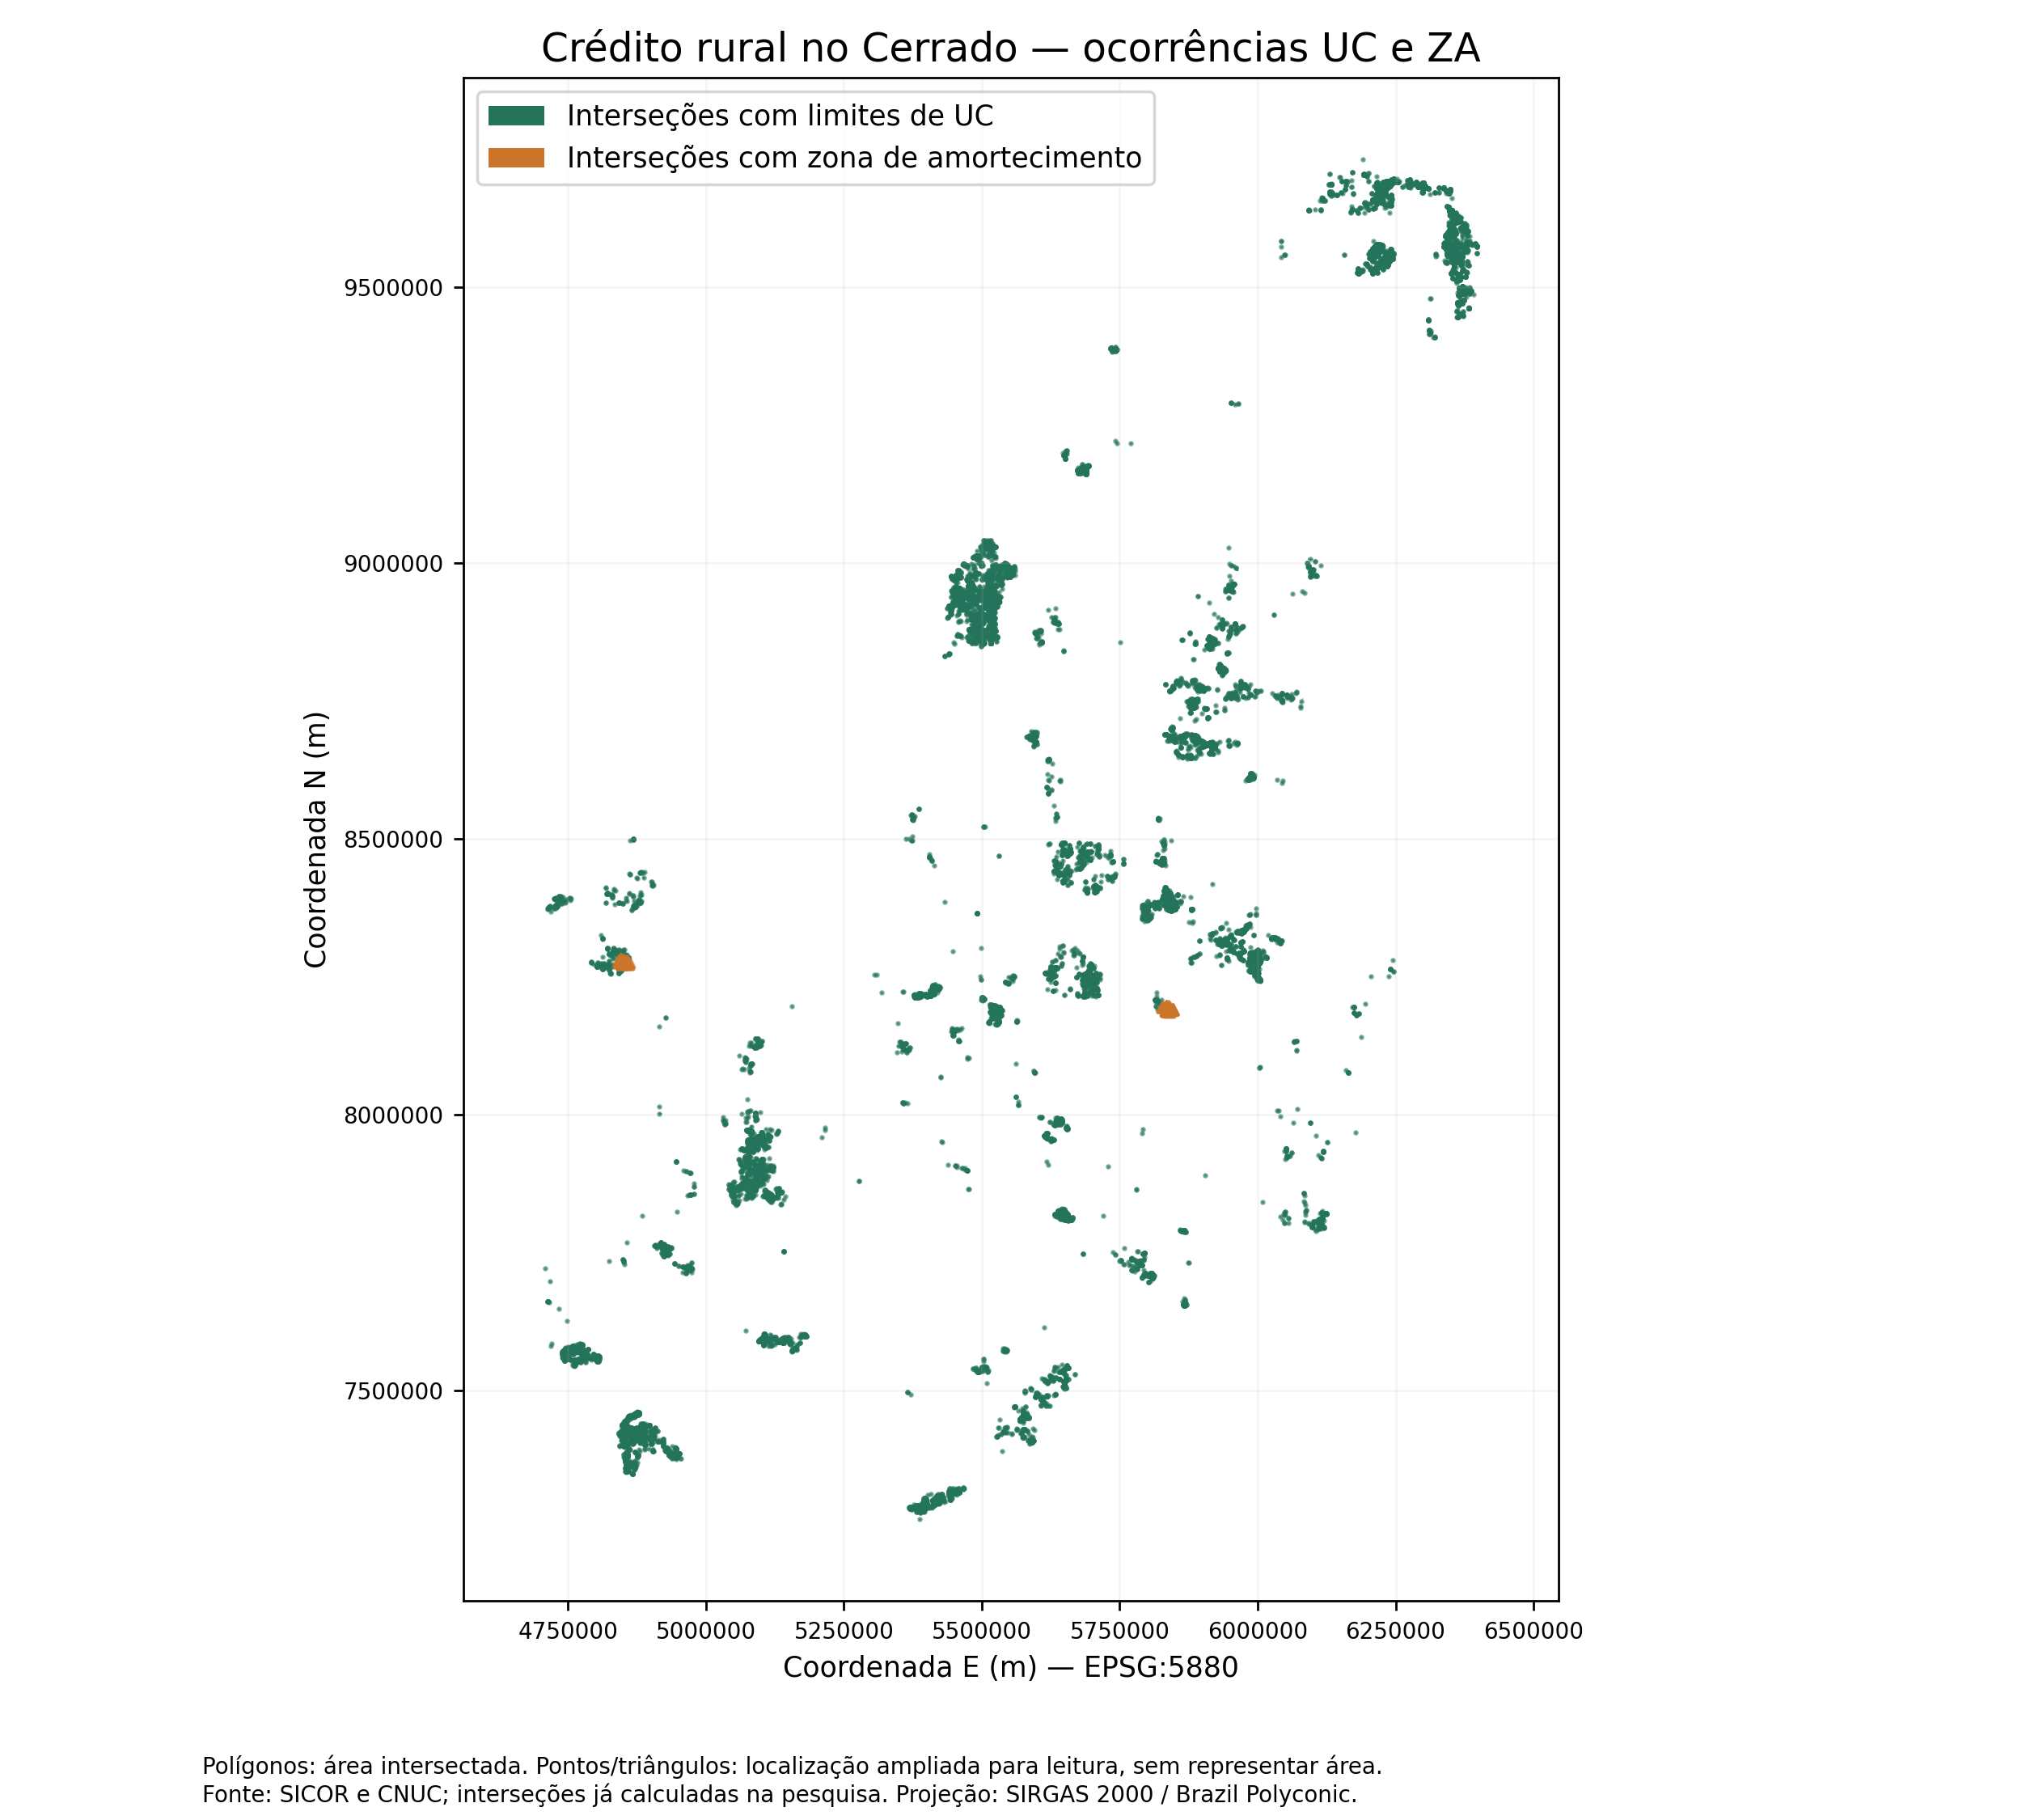

{
  "status": "CONCLUIDO",
  "origem": "/content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/intersecoes/unidades de conservacao/resultados_por_id_gleba2/versao_2/bases_analiticas/base_completa_sem_deduplicacao.csv",
  "id_drive_origem": "1GWw06MzWnz66l4x5aPX9T4l91vcoRxmc",
  "tamanho_bytes": 12743853707,
  "intersecoes_refeitas": false,
  "word_atualizado": false,
  "sha256_atributos": "2156d291ad16eead95feec9d239f775fbf0a4fb4ff6db9e4eceb0e68ffb5abb8",
  "registros": 18617,
  "registros_uc": 18493,
  "registros_za": 124,
  "reparos_geometricos": 2,
  "divergencias_area": 0,
  "crs_geometria_entrada": "EPSG:4326",
  "crs_calculo_area": "EPSG:5880",
  "resumos_outras_camadas": "Tabelas da revisão documental copiadas em apoio_seis_campos; não foram recalculadas uniões das outras camadas.",
  "versoes": {
    "pandas": "2.2.3",
    "shapely": "2.1.2",
    "pyproj": "3.8.0",
    "matplotlib": "3.10.0"
  }
}
PASTA GERADA: /content/drive/MyDrive/Produto_dissertaca

In [6]:
from IPython.display import display, Image
status_final = json.loads((PASTA_RESULTADO / 'status.json').read_text())
assert status_final['status'] == 'CONCLUIDO'
display(RESUMO)
display(Image(filename=str(PASTA_RESULTADO / 'mapa_ocorrencias_uc_za.png'), width=850))
print(json.dumps(status_final, ensure_ascii=False, indent=2))
print('PASTA GERADA:', PASTA_RESULTADO)
print('ZIP GERADO:', str(PASTA_RESULTADO) + '.zip')


## 7. Aplicar os resultados à dissertação

1. Substituir a síntese de unidades de conservação pelo recorte `uc` de `resumo_geral_uc_za.csv`; apresentar `za` separadamente. Manter `todos` apenas quando a legenda indicar expressamente o conjunto UC + ZA.
2. Usar `area_uniao_ha` para área física, sem somar as uniões das categorias ou unidades. Consultar `reconciliacao_areas.csv` para a área comum aos dois recortes.
3. Conferir contagens de operações, glebas e unidades com `reconciliacao_identificadores.csv`. Não subtrair 124 do número de operações: 124 é número de **linhas**.
4. Substituir ou corrigir as legendas das figuras que tratavam ZA como interior de UC. Os mapas gerados mostram **interseções**, com pontos ampliados para localização nos mapas gerais. Não mostram os perímetros completos das unidades, limites estaduais ou o limite do bioma.
5. Conferir os trechos que usam os seis campos auxiliares com a revisão documental anterior:

| Camada / campo auxiliar | Interpretação e campo de referência |
|---|---|
| Quilombolas / `_TIPOLOGIA_2` | Rótulo de `TIPO_IMPEDIMENTO`; não representa modalidade territorial. |
| Assentamentos / `_TIPOLOGIA_2` | Classe do produtor (`TIPO_PRODUTOR_ANALISE`); não é tipo de assentamento. |
| Embargos / `_TIPOLOGIA_3` | Classe do produtor. Para tipo de área e infração, consultar `EMB_TIPO_AREA` e `EMB_DES_INFRAC`. |
| Embargos / `_UF_UNIDADE` | Derivado de `UF_OPERACAO`, vazio nos registros revisados; consultar `EMB_UF`. |
| CAR / `_TIPOLOGIA_2` | Classe do produtor; tipo do imóvel está em `CAR_TIPO_IMOVE`. |
| CAR / `_UF_UNIDADE` | Derivado de `UF_OPERACAO`, vazio nos registros revisados; consultar `CAR_UF`. |

As tabelas disponíveis da revisão anterior são copiadas para `apoio_seis_campos`. Esta execução não resolve automaticamente as definições ainda parciais ou desconhecidas do dicionário.

**Limites desta entrega:** `por_uf_cadastrada.csv` agrupa o atributo `UC_UF`, que pode conter mais de uma UF; não é área recortada por estado. Mapas municipais, percentuais do território de cada UC, séries temporais e totais financeiros não são recalculados. A presença de interseção não equivale, por si só, a conclusão jurídica sobre uma operação.

**Próximo passo:** envie o ZIP gerado (ou compartilhe a pasta) e a versão atual da dissertação. Com os resultados conferidos, será possível propor as substituições exatas no texto e nas tabelas. Este notebook não modifica o Word.
